In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df=pd.read_csv("/content/cancer-risk-factors.csv")

In [ ]:
df.head(5)

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,Medium
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,Low
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,Medium


In [ ]:
df.columns

Index(['Patient_ID', 'Cancer_Type', 'Age', 'Gender', 'Smoking', 'Alcohol_Use',
       'Obesity', 'Family_History', 'Diet_Red_Meat', 'Diet_Salted_Processed',
       'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution',
       'Occupational_Hazards', 'BRCA_Mutation', 'H_Pylori_Infection',
       'Calcium_Intake', 'Overall_Risk_Score', 'BMI',
       'Physical_Activity_Level', 'Risk_Level'],
      dtype='object')

In [ ]:
df.Cancer_Type.value_counts()

,count
Cancer_Type,
Lung,527
Breast,460
Colon,418
Prostate,305
Skin,290


In [ ]:
risk_counts= df['Risk_Level'].value_counts()
print (risk_counts)

Risk_Level
Medium    1574
Low        324
High       102
Name: count, dtype: int64


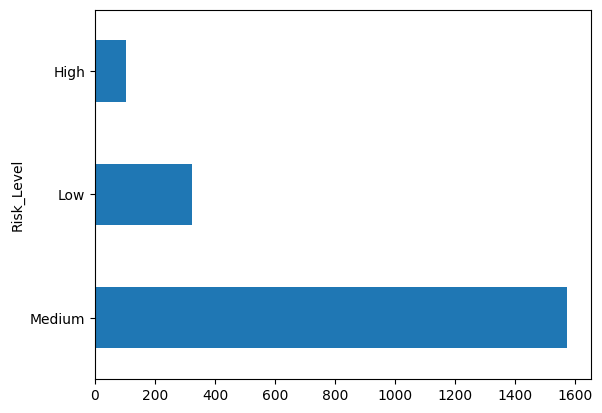

In [ ]:
risk_counts= df['Risk_Level'].value_counts().plot(kind='barh')

In [ ]:
risk_details= df['Risk_Level'].value_counts()/len(df)*100
print(risk_details)

Risk_Level
Medium    78.7
Low       16.2
High       5.1
Name: count, dtype: float64


In [ ]:
df['Gender'].value_counts()

,count
Gender,
0,1022
1,978


<Axes: xlabel='Cancer_Type'>

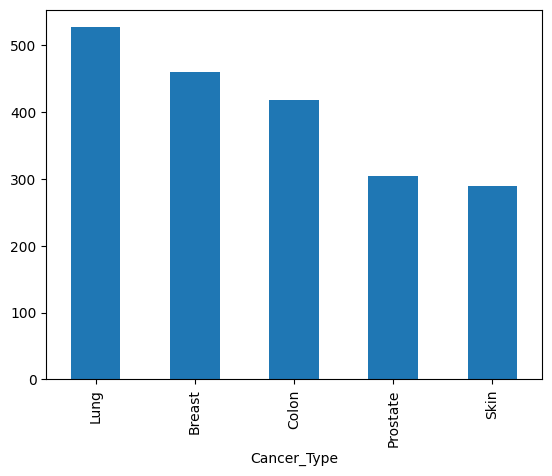

In [ ]:
df['Cancer_Type'].value_counts().plot(kind='bar')

In [ ]:
gender_cancer_counts = df.groupby(['Gender', 'Cancer_Type']).size().reset_index(name='Patient_Count')
gender_cancer_counts["Gender"]=gender_cancer_counts["Gender"].map({0:'Female', 1:'Male'})
print(gender_cancer_counts)

   Gender Cancer_Type  Patient_Count
0  Female      Breast            455
1  Female       Colon            197
2  Female        Lung            238
3  Female        Skin            132
4    Male      Breast              5
5    Male       Colon            221
6    Male        Lung            289
7    Male    Prostate            305
8    Male        Skin            158


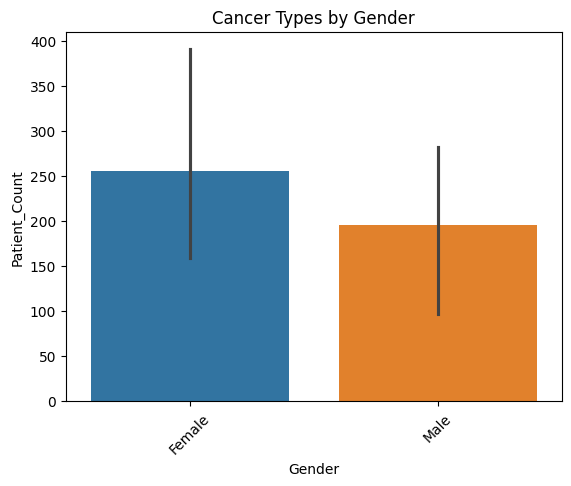

In [ ]:
sns.barplot(data=gender_cancer_counts, x='Gender', y='Patient_Count', hue='Gender')
plt.title('Cancer Types by Gender')
plt.xticks(rotation=45)
plt.show()

In [ ]:
young_patients=df[df['Age']<35]
print(young_patients)

    Patient_ID Cancer_Type  Age  Gender  Smoking  Alcohol_Use  Obesity  \
420     BR0020        Skin   32       0        1            3        8   
433     BR0033        Lung   25       0        8            6        5   
454     BR0054        Lung   29       0        8            6        7   
468     BR0068        Lung   32       0        8            2        0   
495     BR0095      Breast   31       0        1            9       10   
585     BR0185        Lung   34       0        6            8        5   
593     BR0193      Breast   34       0        5            1       10   
621     BR0221        Lung   25       0        7           10        6   
698     BR0298        Lung   34       0        8            0        2   

     Family_History  Diet_Red_Meat  Diet_Salted_Processed  ...  \
420               0              5                      1  ...   
433               0              3                      5  ...   
454               0              3                      0  ..

In [ ]:
count_young=(df['Age']<35).sum()
print(f"Number of patients under 35:{count_young}")

Number of patients under 35:9


In [ ]:
young_cancer_type=df[df['Age']<35]['Cancer_Type'].value_counts()
print(young_cancer_type)

Cancer_Type
Lung      6
Breast    2
Skin      1
Name: count, dtype: int64


In [ ]:
#Finding out which factors contribute to Cancer
#Select only numeric columns
numeric_columns=df.select_dtypes(include=['number'])
#Compute the mean of each numeric feature per risk level
risk_means=df.groupby('Risk_Level')[numeric_columns.columns].mean().T
print(risk_means)

Risk_Level                    High        Low     Medium
Age                      63.745098  63.685185  63.125794
Gender                    0.509804   0.493827   0.486658
Smoking                   7.519608   2.845679   5.479670
Alcohol_Use               7.519608   2.984568   5.296061
Obesity                   7.274510   4.824074   6.118170
Family_History            0.205882   0.138889   0.205210
Diet_Red_Meat             7.362745   3.972222   5.299238
Diet_Salted_Processed     7.039216   2.888889   4.747776
Fruit_Veg_Intake          3.911765   5.666667   4.841169
Physical_Activity         4.921569   3.669753   4.027319
Air_Pollution             8.539216   2.947531   5.603558
Occupational_Hazards      6.990196   3.364198   5.181067
BRCA_Mutation             0.049020   0.037037   0.030496
H_Pylori_Infection        0.245098   0.175926   0.197586
Calcium_Intake            4.323529   3.651235   3.975222
Overall_Risk_Score        0.699991   0.269458   0.476616
BMI                      26.225

In [ ]:
risk_diff=risk_means['High']-risk_means['Low']
risk_diff=risk_diff.sort_values(ascending=False)
print(risk_diff)

Air_Pollution              5.591685
Smoking                    4.673929
Alcohol_Use                4.535040
Diet_Salted_Processed      4.150327
Occupational_Hazards       3.625999
Diet_Red_Meat              3.390523
Obesity                    2.450436
Physical_Activity          1.251816
Calcium_Intake             0.672295
Overall_Risk_Score         0.430533
BMI                        0.410984
Physical_Activity_Level    0.337509
H_Pylori_Infection         0.069172
Family_History             0.066993
Age                        0.059913
Gender                     0.015977
BRCA_Mutation              0.011983
Fruit_Veg_Intake          -1.754902
dtype: float64


In [ ]:
bmi_by_risk=df.groupby('Risk_Level')['BMI'].mean()
print(bmi_by_risk)

Risk_Level
High      26.225490
Low       25.814506
Medium    26.256544
Name: BMI, dtype: float64


In [ ]:
df.head(2)

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium


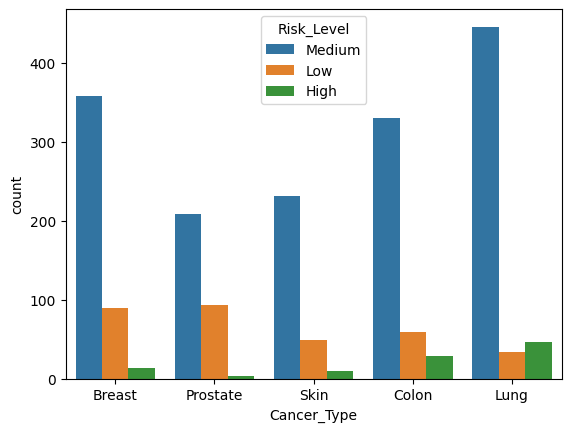

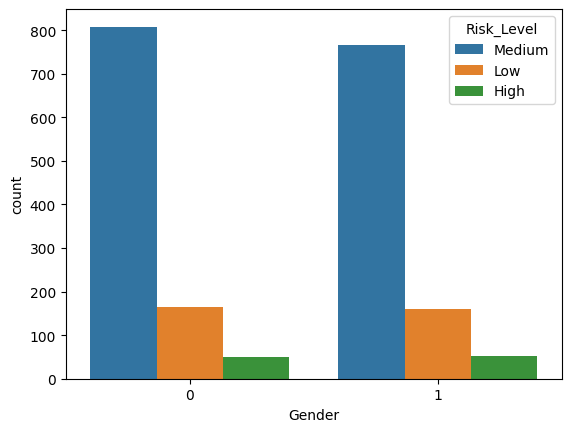

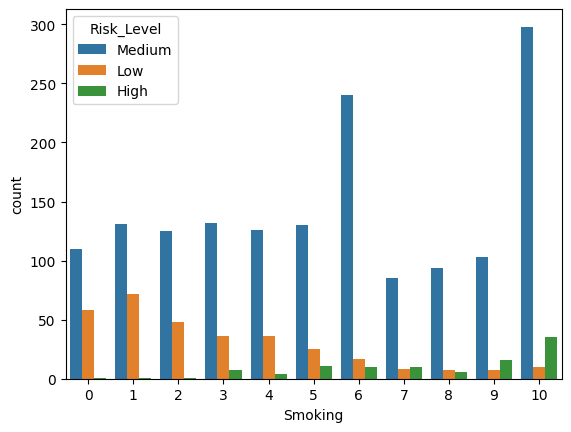

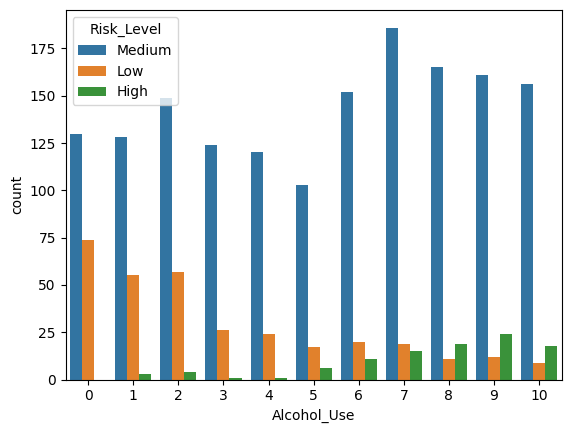

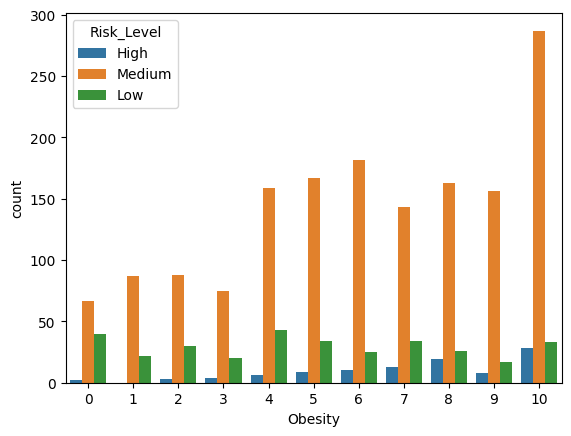

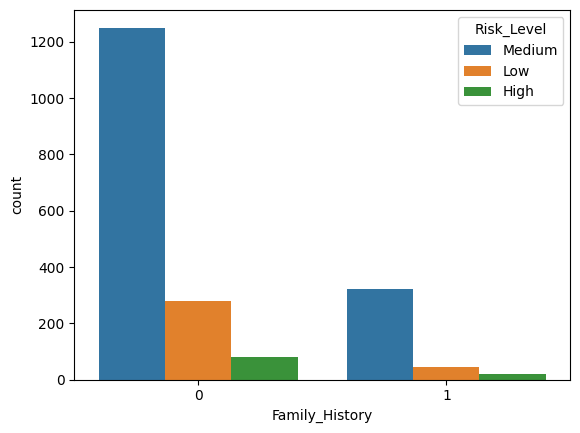

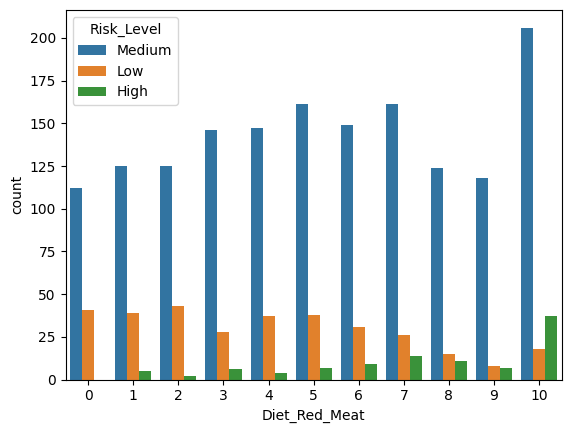

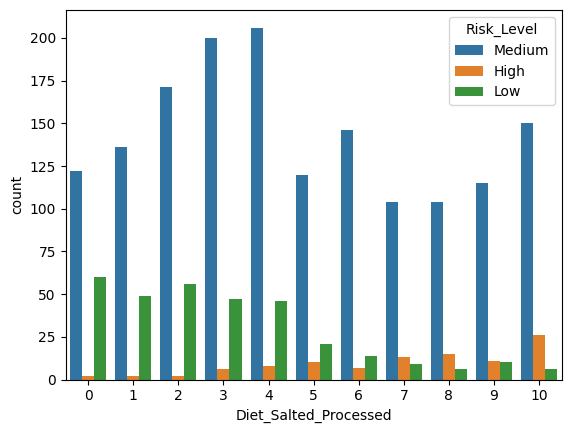

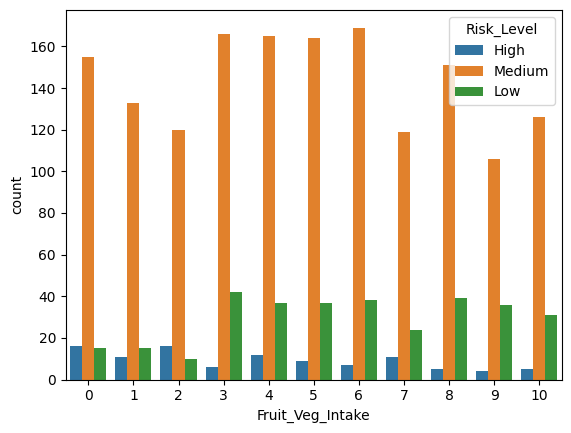

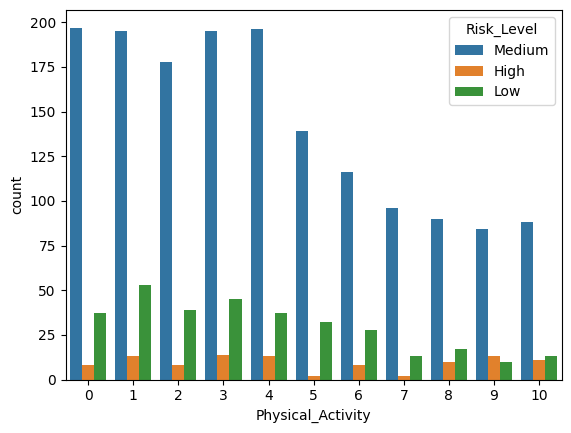

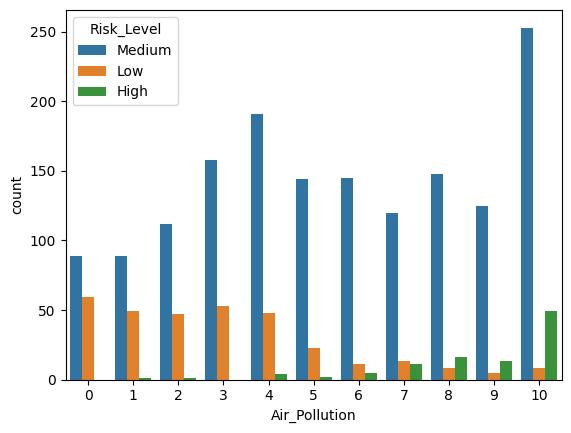

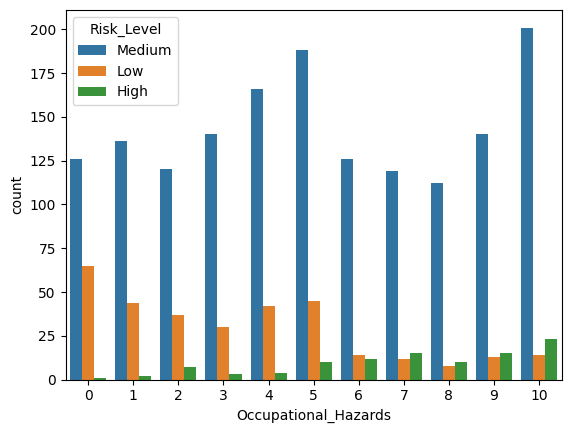

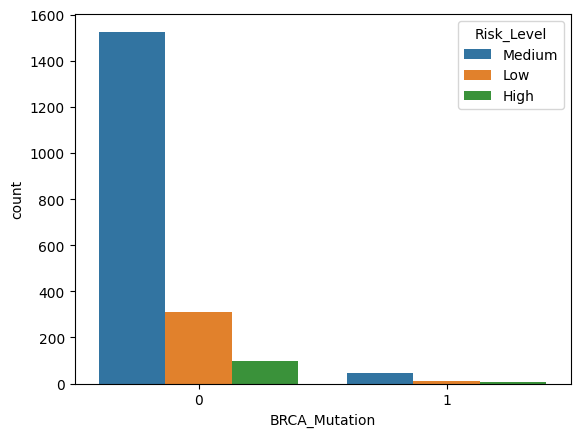

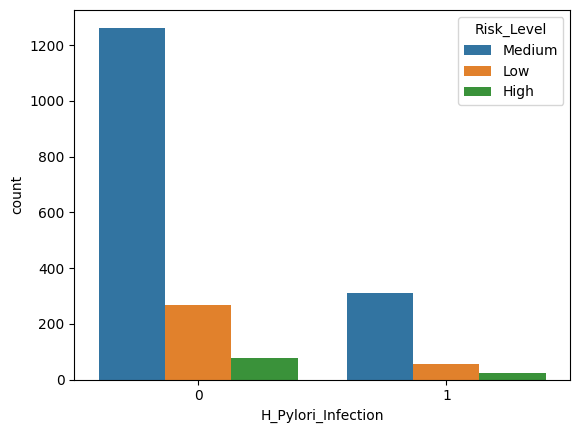

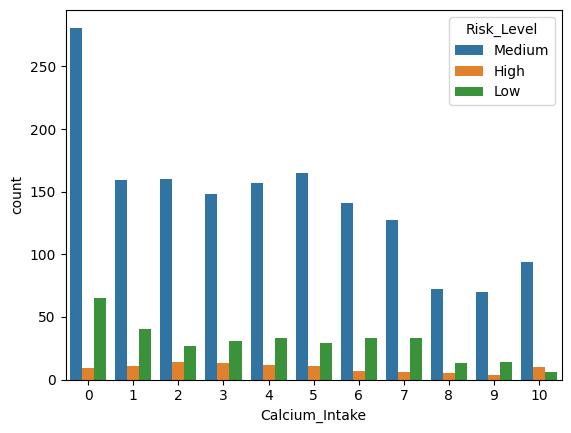

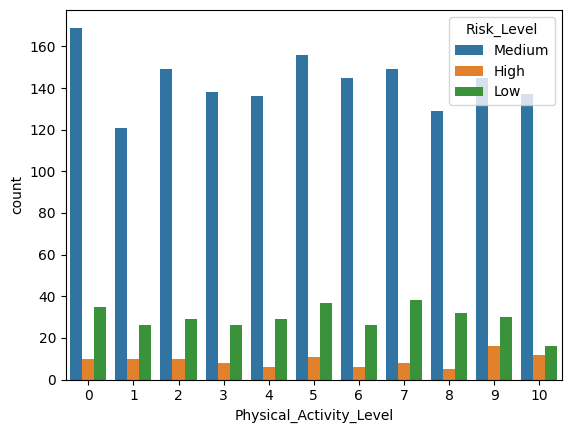

In [ ]:
for i, predictor in enumerate(df.drop(columns= ['Patient_ID', 'Risk_Level', 'Age', 'Overall_Risk_Score', 'BMI'])):
  plt.figure(i)
  sns.countplot(data=df, x=predictor, hue='Risk_Level')

In [ ]:
print(df)

     Patient_ID Cancer_Type  Age  Gender  Smoking  Alcohol_Use  Obesity  \
0        LU0000      Breast   68       0        7            2        8   
1        LU0001    Prostate   74       1        8            9        8   
2        LU0002        Skin   55       1        7           10        7   
3        LU0003       Colon   61       0        6            2        2   
4        LU0004        Lung   67       1       10            7        4   
...         ...         ...  ...     ...      ...          ...      ...   
1995     ST0395       Colon   60       1        4            6        4   
1996     ST0396    Prostate   84       1        5            7        8   
1997     ST0397        Lung   65       0        7            2       10   
1998     ST0398        Lung   64       1       10            2       10   
1999     ST0399      Breast   64       0        3            4       10   

      Family_History  Diet_Red_Meat  Diet_Salted_Processed  ...  \
0                  0            

In [ ]:
df['Risk_Level']=df['Risk_Level'].map({'Low':0, 'Medium':1, 'High':2})

In [ ]:
df.head(5)

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,1
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,1
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,1
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,0
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,1


In [ ]:
df_dummies=pd.get_dummies(df)
df_dummies.head(5)

,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,...,Patient_ID_ST0395,Patient_ID_ST0396,Patient_ID_ST0397,Patient_ID_ST0398,Patient_ID_ST0399,Cancer_Type_Breast,Cancer_Type_Colon,Cancer_Type_Lung,Cancer_Type_Prostate,Cancer_Type_Skin
0,68,0,7,2,8,0,5,3,7,4,...,False,False,False,False,False,True,False,False,False,False
1,74,1,8,9,8,0,0,3,7,1,...,False,False,False,False,False,False,False,False,True,False
2,55,1,7,10,7,0,3,3,4,1,...,False,False,False,False,False,False,False,False,False,True
3,61,0,6,2,2,0,6,2,4,6,...,False,False,False,False,False,False,True,False,False,False
4,67,1,10,7,4,0,6,3,10,9,...,False,False,False,False,False,False,False,True,False,False


<Axes: >

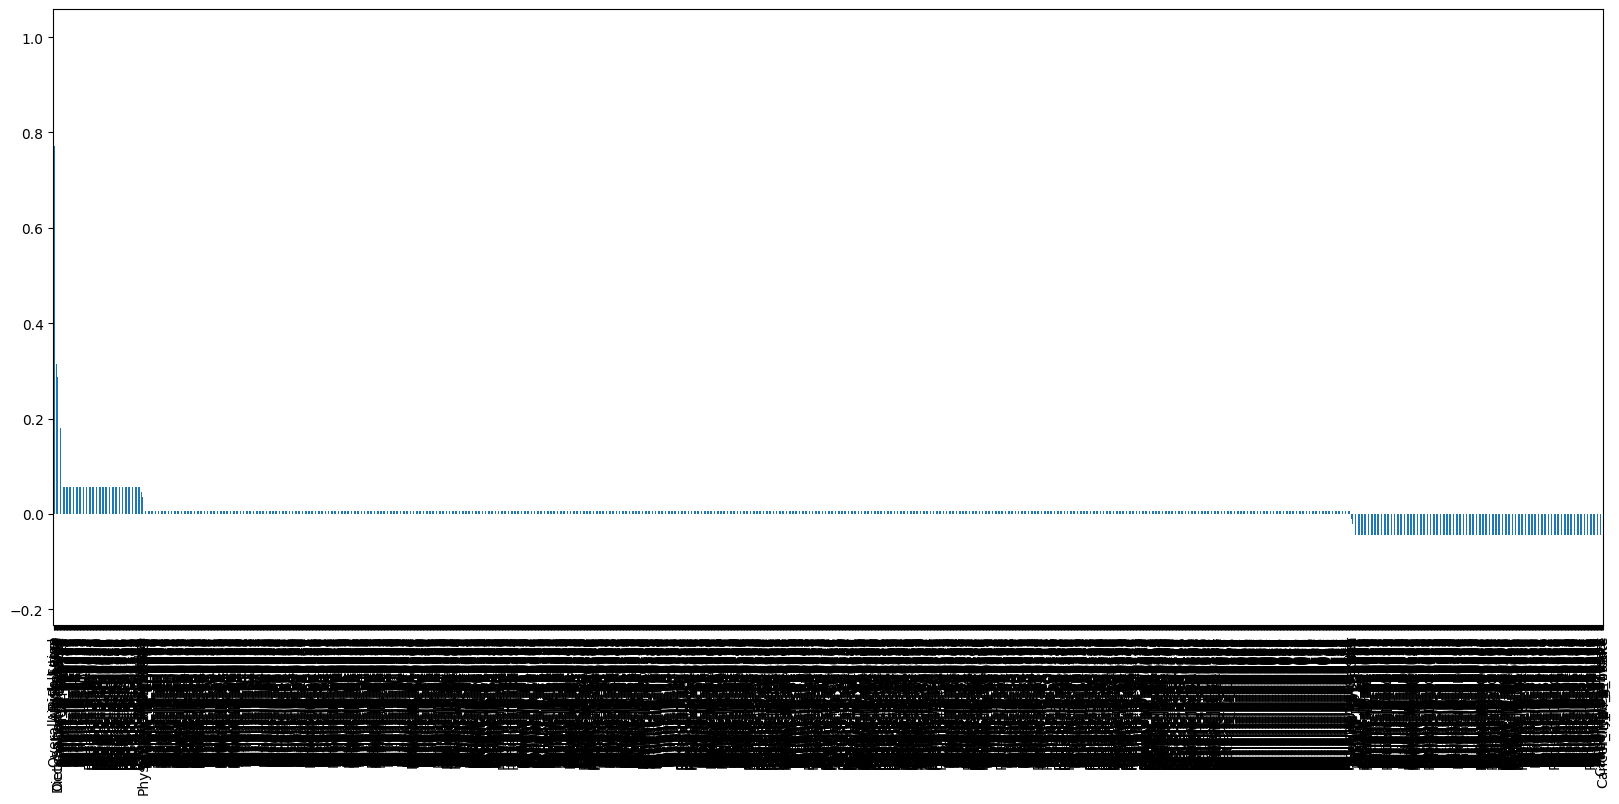

In [ ]:
plt.figure(figsize=(20,8))
df_dummies.corr()['Risk_Level'].sort_values(ascending=False).plot(kind='bar')

In [ ]:
df1=pd.read_csv('/content/cancer-risk-factors.csv')

In [ ]:
df1.head(5)

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,Medium
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,Low
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,Medium


In [ ]:
x=df1.drop(columns=['Patient_ID', 'Risk_Level', 'Cancer_Type'])
le=LabelEncoder()
y=le.fit_transform(df1['Risk_Level'])
x

,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level
0,68,0,7,2,8,0,5,3,7,4,6,3,1,0,0,0.398696,28.0,5
1,74,1,8,9,8,0,0,3,7,1,3,3,0,0,5,0.424299,25.4,9
2,55,1,7,10,7,0,3,3,4,1,8,10,0,0,6,0.605082,28.6,2
3,61,0,6,2,2,0,6,2,4,6,4,8,0,0,8,0.318449,32.1,7
4,67,1,10,7,4,0,6,3,10,9,10,9,0,0,5,0.524358,25.1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,60,1,4,6,4,0,10,6,4,4,5,3,1,0,4,0.437539,30.3,3
1996,84,1,5,7,8,0,10,0,1,2,1,3,0,0,2,0.451128,25.9,4
1997,65,0,7,2,10,0,4,2,2,3,6,0,0,1,0,0.295760,22.5,3
1998,64,1,10,2,10,0,2,10,7,5,4,2,0,0,10,0.422201,25.3,3


In [ ]:
y

array([2, 2, 2, ..., 1, 2, 2], shape=(2000,))

In [ ]:
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [ ]:
model=RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(x_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred=model.predict(x_test_scaled)
print("Classification Report")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Classification Report
              precision    recall  f1-score   support

        High       1.00      0.95      0.97        20
         Low       1.00      1.00      1.00        65
      Medium       1.00      1.00      1.00       315

    accuracy                           1.00       400
   macro avg       1.00      0.98      0.99       400
weighted avg       1.00      1.00      1.00       400



In [ ]:
cm=confusion_matrix(y_test, y_pred)
print("Confusion Matrix")
print(cm)

Confusion Matrix
[[ 19   0   1]
 [  0  65   0]
 [  0   0 315]]


In [ ]:
log_reg_model=LogisticRegression(random_state=42)
log_reg_model.fit(x_train_scaled, y_train)

LogisticRegression(random_state=42)

In [ ]:
y_pred_log_reg=log_reg_model.predict(x_test_scaled)
print("Classification Report")
print(classification_report(y_test, y_pred_log_reg, target_names=le.classes_))

Classification Report
              precision    recall  f1-score   support

        High       1.00      0.80      0.89        20
         Low       0.97      0.95      0.96        65
      Medium       0.98      0.99      0.99       315

    accuracy                           0.98       400
   macro avg       0.98      0.92      0.95       400
weighted avg       0.98      0.98      0.98       400



In [ ]:
cm=confusion_matrix(y_test, y_pred_log_reg)
print("Confusion Matrix")
print(cm)

Confusion Matrix
[[ 16   0   4]
 [  0  62   3]
 [  0   2 313]]


In [ ]:
#Remove the col Overall Risk Score
x_new=df.drop(columns=['Patient_ID', 'Risk_Level', 'Cancer_Type', 'Overall_Risk_Score'])
le_new=LabelEncoder()
y_new=le.fit_transform(df['Risk_Level'])

In [ ]:
x_train_new, x_test_new, y_train_new, y_test_new=train_test_split(x_new,y_new, test_size=0.2, random_state=42, stratify=y)

In [ ]:
scaler_new=StandardScaler()
x_train_scaled_new=scaler_new.fit_transform(x_train_new)
x_test_scaled_new=scaler_new.transform(x_test_new)

In [ ]:
model_new=RandomForestClassifier(random_state=42, n_estimators=100)
model_new.fit(x_train_scaled_new, y_train_new)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred_new=model_new.predict(x_test_scaled_new)
print("Classification Report")
print(classification_report(y_test_new, y_pred_new, target_names=[str(c) for c in le.classes_]))

Classification Report
              precision    recall  f1-score   support

           0       0.85      0.34      0.48        65
           1       0.83      0.99      0.90       315
           2       1.00      0.05      0.10        20

    accuracy                           0.83       400
   macro avg       0.89      0.46      0.49       400
weighted avg       0.84      0.83      0.80       400



In [ ]:
cm=confusion_matrix(y_test_new, y_pred_new)
print("Confusion Matrix")
print(cm)

Confusion Matrix
[[ 22  43   0]
 [  4 311   0]
 [  0  19   1]]


In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [ ]:
smote=SMOTE(random_state=42)
x_train_res, y_train_res=smote.fit_resample(x_train_scaled_new, y_train_new)
print("Class distribution after SMOTE")
print(pd.Series(y_train_res).value_counts())

Class distribution after SMOTE
1    1259
0    1259
2    1259
Name: count, dtype: int64


In [ ]:
rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(x_train_res, y_train_res)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred_2=rf_model.predict(x_test_scaled_new)
print("Classification Report")
print(classification_report(y_test_new, y_pred_2, target_names=[str(c) for c in le.classes_]))

Classification Report
              precision    recall  f1-score   support

           0       0.72      0.63      0.67        65
           1       0.89      0.93      0.91       315
           2       0.55      0.30      0.39        20

    accuracy                           0.85       400
   macro avg       0.72      0.62      0.66       400
weighted avg       0.84      0.85      0.84       400



In [ ]:
cm=confusion_matrix(y_test_new, y_pred_2)
print("Confusion Matrix")
print(cm)

Confusion Matrix
[[ 41  24   0]
 [ 16 294   5]
 [  0  14   6]]


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna
from optuna.samplers import TPESampler
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np
import joblib

#

In [ ]:
from sklearn.metrics import f1_score, make_scorer
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')
scorer=make_scorer(macro_f1)

In [ ]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scores = []

X_arr = np.asarray(x_train_res)
y_arr = np.asarray(y_train_res)

for train_idx, val_idx in cv.split(X_arr, y_arr):

    X_t, X_v = X_arr[train_idx], X_arr[val_idx]
    y_t, y_v = y_arr[train_idx], y_arr[val_idx]

    model.fit(X_t, y_t)

    y_pred = model.predict(X_v)

    score = f1_score(
        y_v,
        y_pred,
        average='macro'
    )

    scores.append(score)

mean_score = np.mean(scores)
print(f"Mean Macro F1 Score: {mean_score}")

Mean Macro F1 Score: 0.9553886508250192


In [ ]:
sampler = TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler, study_name='rf_macro_f1')

[I 2026-11-09 04:27:09,179] A new study created in memory with name: rf_macro_f1


In [ ]:
def objective(trial):
    # --- Define hyperparameter search space ---
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 5, 30, log=True),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'bootstrap': trial.suggest_categorical('bootstrap', [True, False]),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'random_state': 42,
        'n_jobs': -1
    }

    # --- Perform Cross-Validation ---
    scores = []
    X_arr = np.asarray(x_train_res)
    y_arr = np.asarray(y_train_res)

    for train_idx, val_idx in cv.split(X_arr, y_arr):
        X_t, X_v = X_arr[train_idx], X_arr[val_idx]
        y_t, y_v = y_arr[train_idx], y_arr[val_idx]

        clf = RandomForestClassifier(**params)
        clf.fit(X_t, y_t)
        y_pred = clf.predict(X_v)

        score = f1_score(y_v, y_pred, average='macro')
        scores.append(score)

    return np.mean(scores)

# --- Run optimization ---
n_trials = 50  # change to 100+ if you want more thorough search
study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

print("Best trial:")
print("  Value (macro F1):", study.best_value)
print("  Params:")
for k, v in study.best_params.items():
    print(f"    {k}: {v}")

  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-11-09 04:27:13,555] Trial 0 finished with value: 0.9342541980580811 and parameters: {'n_estimators': 144, 'max_depth': 28, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'bootstrap': True, 'criterion': 'gini'}. Best is trial 0 with value: 0.9342541980580811.
[I 2026-11-09 04:27:49,906] Trial 1 finished with value: 0.9354517330363339 and parameters: {'n_estimators': 293, 'max_depth': 22, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': None, 'bootstrap': True, 'criterion': 'gini'}. Best is trial 1 with value: 0.9354517330363339.
[W 2026-11-09 04:27:54,974] Trial 2 failed with parameters: {'n_estimators': 123, 'max_depth': 9, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': None, 'bootstrap': False, 'criterion': 'gini'} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = 

KeyboardInterrupt: 

In [ ]:
# Train final model with best params and full training data, then evaluate on test
best_params = {
    'n_estimators': 218,
    'max_depth': 17,
    'min_samples_split': 4,
    'min_samples_leaf': 1,
    'max_features': 'log2',
    'bootstrap': False,
    'criterion': 'entropy',
    'random_state': 42,
    'n_jobs': -1
}

final_rf = RandomForestClassifier(**best_params)
final_rf.fit(x_train_res, y_train_res)         # resampled training set

# Fix: Use the scaled test data with the same 17 features, and compare with y_test_new
y_pred_test = final_rf.predict(x_test_scaled_new)

from sklearn.metrics import classification_report, confusion_matrix
print("Classification Report:")
print(classification_report(y_test_new, y_pred_test, target_names=[str(c) for c in le.classes_]))

print("Confusion Matrix:")
print(confusion_matrix(y_test_new, y_pred_test))

In [ ]:
print("Training features:", x_train_new.shape[1])
print("Testing features:", x_test_new.shape[1])

print("\nFeatures in training but not testing:")
print(set(x_train_new.columns) - set(x_test_new.columns))

print("\nFeatures in testing but not training:")
print(set(x_test_new.columns) - set(x_train_new.columns))

In [ ]:
print("Original training shape:", x_train.shape)
print("Original testing shape:", x_test.shape)
print("After SMOTE:", x_train_res.shape)

print("Original training columns:")
print(x_train.columns.tolist())

print("Original testing columns:")
print(x_test.columns.tolist())

In [ ]:
train_features = set(x_train.columns)
test_features = set(x_test.columns)

print("Missing in test:", train_features - test_features)
print("Extra in test:", test_features - train_features)

In [ ]:
print(type(x_train_res))
print(type(x_test))

In [ ]:
from xgboost import XGBClassifier

le = LabelEncoder()
le.fit(y_train)

y_train_enc = le.transform(y_train)
y_test_enc = le.transform(y_test)

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    n_jobs=-1
)

# Set up pipeline with SMOTE and XGBoost
pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', xgb)
])

# Train using the clean features without target leakage
pipe.fit(x_train_new, y_train_new)

# Predict on the clean test features
y_pred_xgb = pipe.predict(x_test_new)

print("Classification Report for XGBoost:")
print(classification_report(y_test_new, y_pred_xgb, target_names=[str(c) for c in le.classes_]))

In [ ]:
y_pred = le.inverse_transform(y_pred_xgb)

In [ ]:
TARGET_LABEL = 'High'
N_TRIALS = 40
CV_FOLDS = 3

In [ ]:
def objective(trial):
    # --- Define hyperparameter search space for XGBoost ---
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'n_jobs': -1
    }

    # --- Perform Cross-Validation ---
    scores = []
    X_arr = np.asarray(x_train_res)
    y_arr = np.asarray(y_train_res)

    for train_idx, val_idx in cv.split(X_arr, y_arr):
        X_t, X_v = X_arr[train_idx], X_arr[val_idx]
        y_t, y_v = y_arr[train_idx], y_arr[val_idx]

        clf = XGBClassifier(**params)
        clf.fit(X_t, y_t)
        y_pred = clf.predict(X_v)

        # Evaluate using macro F1 score
        score = f1_score(y_v, y_pred, average='macro')
        scores.append(score)

    return np.mean(scores)

In [ ]:
from sklearn.metrics import recall_score
import numpy as np

# Dynamic setup based on your variables
target_class_label = 2  # 2 corresponds to 'High' in le.classes_
recalls = []

# Use the correct, clean non-target-leakage variables
for train_idx, val_idx in cv.split(x_train_new, y_train_new):
    X_t, X_v = x_train_new.iloc[train_idx], x_train_new.iloc[val_idx]
    y_t, y_v = y_train_new[train_idx], y_train_new[val_idx]

    # Fit the imbalanced-learn pipeline (pipe)
    pipe.fit(X_t, y_t)
    y_pred = pipe.predict(X_v)

    # Calculate raw class recalls
    recs = recall_score(
        y_v,
        y_pred,
        labels=list(range(len(le.classes_))),
        average=None,
        zero_division=0
    )

    # Extract recall for High Risk class (class index 2)
    recall_high = recs[target_class_label]
    recalls.append(recall_high)

mean_recall_high = float(np.mean(recalls))
print(f"Mean Recall for 'High' Risk Class: {mean_recall_high:.4f}")

In [ ]:
recall_high = recs[target_class_label]

In [ ]:
classes, counts = np.unique(
    y_train_enc,
    return_counts=True
)

class_weights = {
    cls: max(counts) / count
    for cls, count in zip(classes, counts)
}

In [ ]:
sample_weights = np.array([
    class_weights[y] for y in y_train_enc
])

In [ ]:
from xgboost import XGBClassifier

# Instantiate the weighted XGBoost classifier
xgb_weighted = XGBClassifier(
    random_state=42,
    n_jobs=-1
)

# Fit using the clean, non-target-leakage dataset and pre-calculated sample weights
xgb_weighted.fit(
    x_train_new,
    y_train_new,
    sample_weight=sample_weights
)

Optuna Tuned Class weighted XGBoost

In [ ]:
classes, counts = np.unique(y_t, return_counts=True)

class_weight_map = {
    cls: float(max(counts) / cnt)
    for cls, cnt in zip(classes, counts)
}

sample_weights = np.array([
    class_weight_map[y] for y in y_t
])

In [ ]:
# Define default parameters explicitly to resolve the NameError
params = {
    'n_estimators': 100,
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8
}

model = XGBClassifier(
    **params,
    n_jobs=1,
    random_state=42
)

# Train using the slice variables available in your current session
model.fit(
    X_t,
    y_t,
    sample_weight=sample_weights,
    verbose=False
)

In [ ]:
y_pred = model.predict(X_v)

scores.append(
    f1_score(y_v, y_pred, average='macro')
)

In [ ]:
# Evaluate the final class-weighted XGBoost model on the clean test set
y_pred_xgb_weighted = xgb_weighted.predict(x_test_new)

print("Classification Report (Weighted XGBoost on Clean Test Set):")
print(classification_report(y_test_new, y_pred_xgb_weighted, target_names=[str(c) for c in le.classes_]))

print("Confusion Matrix:")
print(confusion_matrix(y_test_new, y_pred_xgb_weighted))